# Demanda y dotación de call center: Evaluación y conclusiones

Ejecuta la etapa anterior primero. Las cifras y conclusiones siguientes se calculan con los datos de esta ejecución; no edites manualmente sus valores. Consulta [metodología](../docs/metodologia.md) para interpretar resultados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("call_center_staffing")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from call_center_staffing.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Demanda y dotación de call center: evaluacion

En **360 intervalos de test**, MAE **1.612**, frente a **1.607** del baseline: el modelo **no mejora** ese error. Erlang C estima hasta **3 agentes programables por intervalo**, y **5** bajo +20 % de volumen. El **12.22%** de intervalos queda bajo el objetivo teórico al sustituir el volumen por el observado. Eso es un diagnóstico del modelo de colas, **no un SLA medido**. AHT fijo, horario y shrinkage son supuestos; no se optimizan turnos, descansos ni rutas por habilidad. Erlang C no incluye abandono, aunque el archivo contiene llamadas no atendidas.


,Indicador,Valor
0,aht_estimado_train_segundos,256.842126
1,target_service_level,0.800000
2,target_wait_seconds,20.000000
3,max_occupancy,0.850000
4,shrinkage,0.300000
5,agentes_programables_maximo,3.000000
6,proporcion_intervalos_sl_teorico_bajo_objetivo,0.122222
7,escenario_mas20pct_maximo,5.000000


,casos,mae,rmse
baseline,360.0,1.607044,2.155667
modelo,360.0,1.611780,2.142630


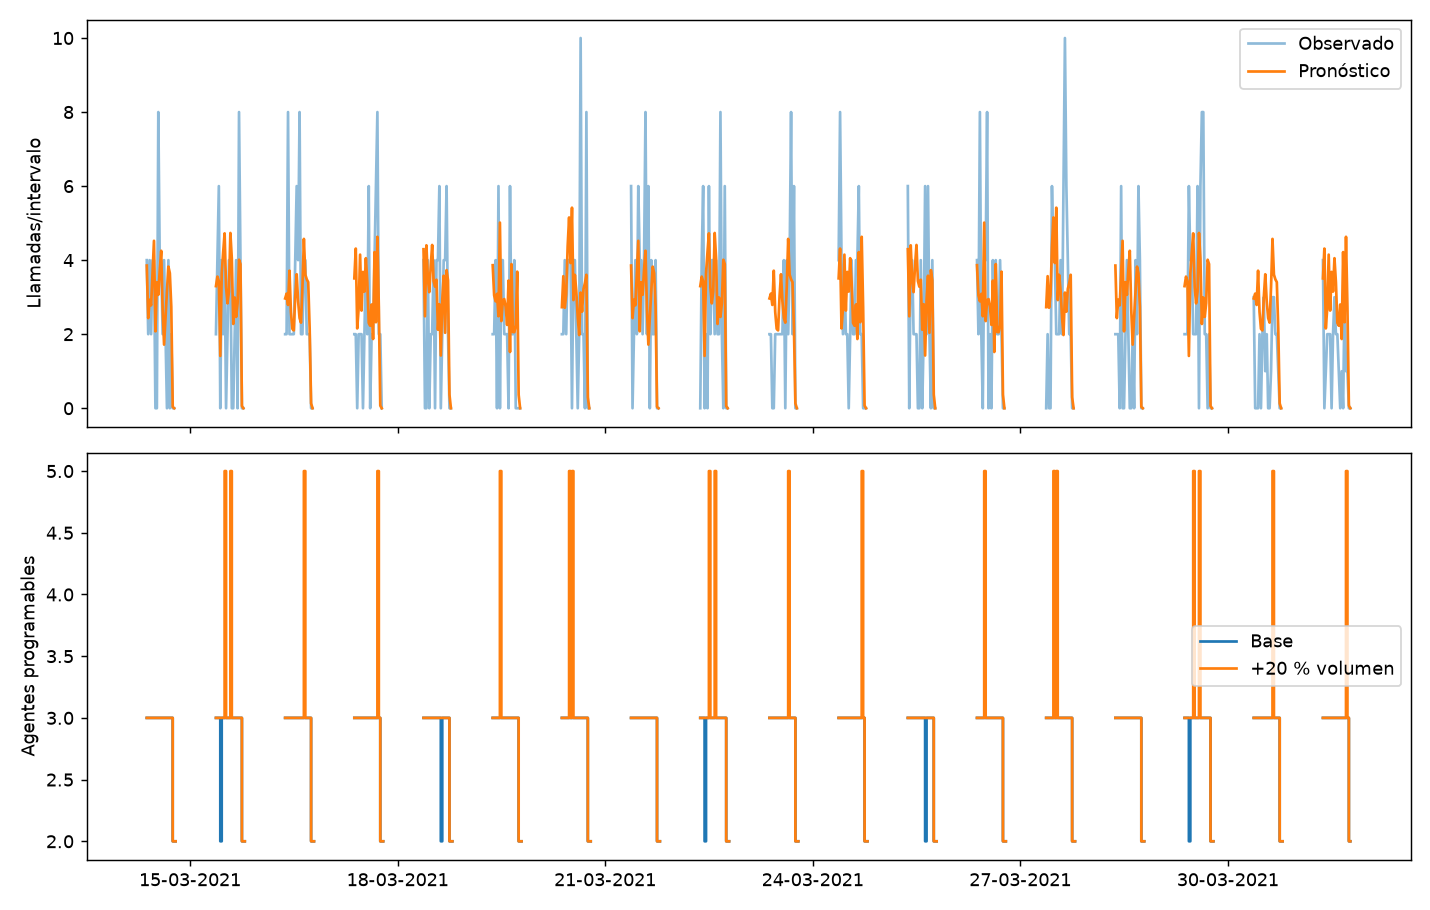

,timestamp,llamadas_observadas,llamadas_pronosticadas,agentes_netos,agentes_programables,agentes_requeridos_segun_observado,agentes_programables_mas20pct,sl_teorico_segun_observado
0,2021-03-14 09:00:00,4,3.853684,2,3,2,3,0.886626
1,2021-03-14 09:30:00,2,2.434067,2,3,2,3,0.968818
2,2021-03-14 10:00:00,4,2.931136,2,3,2,3,0.886626
3,2021-03-14 10:30:00,2,2.779075,2,3,2,3,0.968818
4,2021-03-14 11:00:00,4,3.677885,2,3,2,3,0.886626
5,2021-03-14 11:30:00,4,4.522445,2,3,2,3,0.886626
6,2021-03-14 12:00:00,0,2.076881,2,3,0,3,1.000000
7,2021-03-14 12:30:00,0,3.404233,2,3,0,3,1.000000
8,2021-03-14 13:00:00,8,3.063332,2,3,3,3,0.612032
9,2021-03-14 13:30:00,4,3.740189,2,3,2,3,0.886626


In [2]:
from call_center_staffing.analysis import run_stage
import pandas as pd
metrics, comment = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comment))
scalars = {k: v for k, v in metrics.items() if not isinstance(v, (dict, list))}
if scalars:
    display(pd.DataFrame(list(scalars.items()), columns=["Indicador", "Valor"]))
if "candidatos" in metrics:
    display(pd.DataFrame(metrics["candidatos"]))
if "baseline" in metrics and "modelo" in metrics:
    comparison = {key: {k: v for k, v in metrics[key].items() if not isinstance(v, (dict, list))} for key in ["baseline", "modelo"]}
    display(pd.DataFrame(comparison).T)
if "clasificacion" in metrics.get("modelo", {}):
    display(pd.DataFrame(metrics["modelo"]["clasificacion"]).T)
for image_name in ["eda.png", "evaluacion.png"]:
    image_path = PROJECT_ROOT / "reports/evaluacion" / image_name
    if image_path.exists():
        display(Image(filename=str(image_path)))
display(pd.read_csv(PROJECT_ROOT / "reports/evaluacion/dotacion_intervalos.csv").head(10))


In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from call_center_staffing.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))


[Abrir informe integral](../reports/informe_final/informe_final.md)